# Full statistics: every model, every test

Every number is read from saved files in `evidence/15_model_v3/`; nothing is re-run.

- Alert level chosen on the **validation** set (424 screens); the **test** set (425 screens) scored **once** per model.
- No test screen was trained on. Rico splits are grouped by app; OwlEye screens were checked for near-duplicates.
- AUC does not depend on the alert level. F1, precision and recall do, so read them with the threshold sweep.


In [1]:
import json, os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

C3 = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / 'evidence' / '15_model_v3').exists())
EV = C3 / 'evidence' / '15_model_v3'
FILES = {   # label -> (test scores file, validation scores file or None, fixed threshold or None)
    'v1 shipped (before)':        ('v1_on_v3test_scores.json', None, 0.5351),
    'v3 vision (retrained)':      ('v3_test_scores.json', 'v3_val_scores.json', None),
    'v3 fusion (+ layout text)':  ('v3_fusion_test_scores.json', 'v3_fusion_val_scores.json', None),
    'base, screenshot only':      ('base_vision_test_scores.json', None, 0.5),
    'base, + layout text':        ('base_fusion_test_scores.json', None, 0.5),
}
def load(name):
    p = EV / name
    return json.loads(p.read_text(encoding='utf-8')) if p.exists() else None
def recs(d):
    return [dict(p=float(r['p_defect']), gold=(r['gold_has'] is True or str(r['gold_has']).lower() == 'true'),
                 src='OwlEye' if 'OwlEye' in r['image'] else 'Rico', image=r['image'], gtype=r.get('gold_type')) for r in d['records']]
def auc(y, s):
    y, s = np.asarray(y, bool), np.asarray(s, float)
    pos, neg = s[y], s[~y]
    if len(pos) == 0 or len(neg) == 0: return float('nan')
    return float(((pos[:, None] > neg[None, :]) + 0.5 * (pos[:, None] == neg[None, :])).mean())
def boot_ci(y, s, n=1000, seed=0):
    rng = np.random.default_rng(seed); y, s = np.asarray(y, bool), np.asarray(s, float); out = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y)); a = auc(y[i], s[i])
        if a == a: out.append(a)
    return np.percentile(out, [2.5, 97.5])
def at(rs, t):
    tp = sum(r['p'] >= t and r['gold'] for r in rs); fp = sum(r['p'] >= t and not r['gold'] for r in rs)
    fn = sum(r['p'] < t and r['gold'] for r in rs); tn = sum(r['p'] < t and not r['gold'] for r in rs)
    pr = tp / (tp + fp) if tp + fp else 0.0; rc = tp / (tp + fn) if tp + fn else 0.0
    return dict(precision=pr, recall=rc, f1=2 * pr * rc / (pr + rc) if pr + rc else 0.0,
                false_alarm=fp / (fp + tn) if fp + tn else 0.0, accuracy=(tp + tn) / len(rs))
MODELS = {}
for label, (tf, vf, fixed) in FILES.items():
    t = load(tf)
    if t is None: continue
    thr = fixed if fixed is not None else (load(vf)['best_threshold']['threshold'] if vf and load(vf) else 0.5)
    MODELS[label] = dict(recs=recs(t), thr=thr)
print('models found:', list(MODELS))

models found: ['v1 shipped (before)', 'v3 vision (retrained)', 'v3 fusion (+ layout text)', 'base, screenshot only', 'base, + layout text']


## 1. Headline comparison (test set, 425 screens)
The threshold for each model was fixed before looking at the test set: from validation for the retrained models, from the original selection for v1, and 0.5 for the untrained base.

In [2]:
rows = []
for label, m in MODELS.items():
    y = [r['gold'] for r in m['recs']]; s = [r['p'] for r in m['recs']]
    lo, hi = boot_ci(y, s); k = at(m['recs'], m['thr'])
    rows.append((label, m['thr'], auc(y, s), lo, hi, k['f1'], k['precision'], k['recall'], k['false_alarm']))
print(f"{'model':<28}{'thr':>6}{'AUC':>7}{'95% CI':>14}{'F1':>7}{'prec':>7}{'recall':>8}{'false alarms':>14}")
for r in rows:
    print(f"{r[0]:<28}{r[1]:>6.2f}{r[2]:>7.3f}   [{r[3]:.2f},{r[4]:.2f}]{r[5]:>7.3f}{r[6]:>7.2f}{r[7]:>8.2f}{r[8]:>14.0%}")

model                          thr    AUC        95% CI     F1   prec  recall  false alarms
v1 shipped (before)           0.54  0.735   [0.69,0.78]  0.707   0.65    0.78           51%
v3 vision (retrained)         0.30  0.814   [0.77,0.85]  0.775   0.68    0.90           50%
v3 fusion (+ layout text)     0.32  0.753   [0.71,0.80]  0.737   0.65    0.84           54%
base, screenshot only         0.50  0.594   [0.54,0.65]  0.235   0.67    0.14            8%
base, + layout text           0.50  0.502   [0.45,0.56]  0.049   0.55    0.03            3%


## 2. ROC curves
The curve shows every possible trade-off between catching defects and false alarms. The further up and to the left, the better the model separates defect from clean screens.

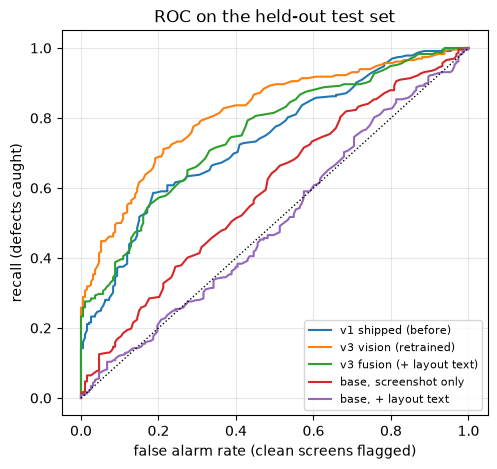

In [3]:
def roc(rs):
    y = np.array([r['gold'] for r in rs]); s = np.array([r['p'] for r in rs]); ts = np.unique(np.concatenate([[0, 1], s]))[::-1]
    return [(((s >= t) & ~y).sum() / (~y).sum(), ((s >= t) & y).sum() / y.sum()) for t in ts]
plt.figure(figsize=(5.5, 5))
for label, m in MODELS.items():
    pts = np.array(roc(m['recs'])); plt.plot(pts[:, 0], pts[:, 1], label=label)
plt.plot([0, 1], [0, 1], 'k:', lw=1); plt.xlabel('false alarm rate (clean screens flagged)'); plt.ylabel('recall (defects caught)')
plt.legend(fontsize=8); plt.grid(alpha=.3); plt.title('ROC on the held-out test set'); plt.show()

## 3. Why recall is high: the threshold sweep (retrained vision arm)
Recall and false alarms move together as the threshold changes. The chosen operating point favours catching defects.

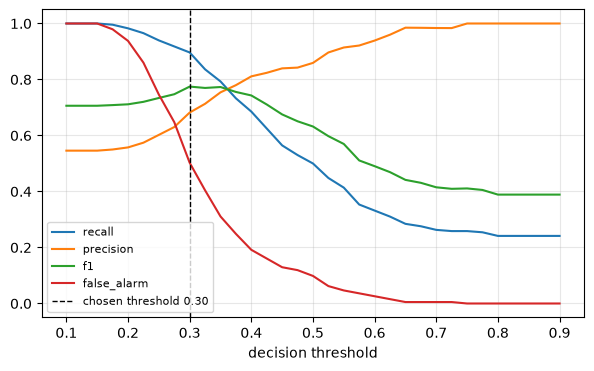

threshold 0.30: precision 0.68, recall 0.90, f1 0.77, false_alarm 0.50, accuracy 0.72
threshold 0.40: precision 0.81, recall 0.69, f1 0.74, false_alarm 0.19, accuracy 0.74
threshold 0.50: precision 0.86, recall 0.50, f1 0.63, false_alarm 0.10, accuracy 0.68


In [4]:
m = MODELS['v3 vision (retrained)']; ts = np.linspace(0.1, 0.9, 33)
ks = [at(m['recs'], t) for t in ts]
plt.figure(figsize=(7, 4))
for key in ('recall', 'precision', 'f1', 'false_alarm'): plt.plot(ts, [k[key] for k in ks], label=key)
plt.axvline(m['thr'], color='k', ls='--', lw=1, label=f"chosen threshold {m['thr']:.2f}"); plt.xlabel('decision threshold'); plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()
for t in (m['thr'], 0.4, 0.5): k = at(m['recs'], t); print(f"threshold {t:.2f}: " + ', '.join(f'{a} {v:.2f}' for a, v in k.items()))

## 4. Score distributions
If scores for defect and clean screens were piled at 0 and 1, that would suggest memorisation or leakage. Here the two groups overlap, which is what a moderate, honest model looks like.

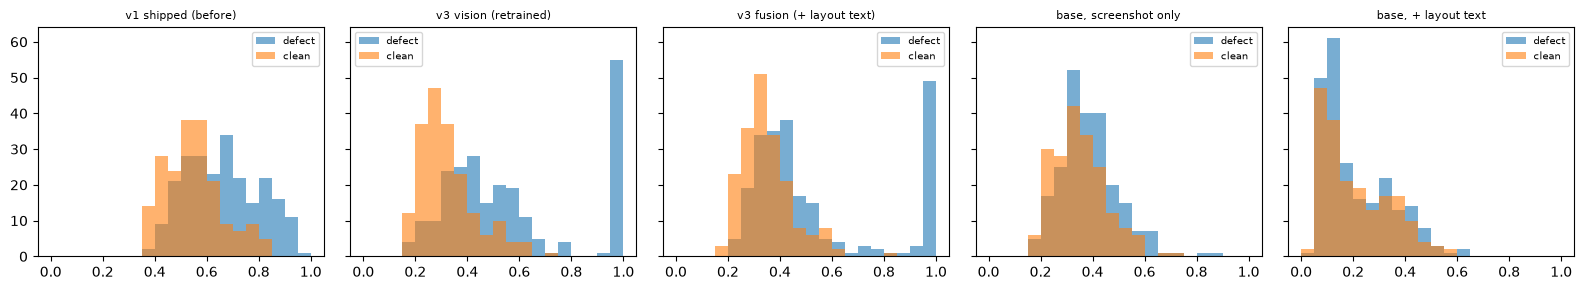

In [5]:
fig, ax = plt.subplots(1, len(MODELS), figsize=(3.2 * len(MODELS), 3), sharey=True, squeeze=False)
for a, (label, m) in zip(ax[0], MODELS.items()):
    a.hist([r['p'] for r in m['recs'] if r['gold']], bins=20, range=(0, 1), alpha=.6, label='defect')
    a.hist([r['p'] for r in m['recs'] if not r['gold']], bins=20, range=(0, 1), alpha=.6, label='clean'); a.set_title(label, fontsize=8); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 5. By data source and defect type (retrained vision arm)

In [6]:
m = MODELS['v3 vision (retrained)']
for src in ('OwlEye', 'Rico'):
    sub = [r for r in m['recs'] if r['src'] == src]; k = at(sub, m['thr'])
    print(f"{src:<7} n={len(sub):<4} AUC {auc([r['gold'] for r in sub], [r['p'] for r in sub]):.3f}  F1 {k['f1']:.2f}  recall {k['recall']:.2f}  false alarms {k['false_alarm']:.0%}")
print()
for t in ('component_overlap', 'data_binding_null', 'missing_component', 'text_truncation'):
    sub = [r for r in m['recs'] if r['gtype'] == t]
    print(f"{t:<20} n={len(sub):<4} caught {sum(r['p'] >= m['thr'] for r in sub) / len(sub):.0%}   mean score {np.mean([r['p'] for r in sub]):.2f}")

OwlEye  n=165  AUC 0.828  F1 0.77  recall 0.90  false alarms 45%
Rico    n=260  AUC 0.803  F1 0.78  recall 0.89  false alarms 55%

component_overlap    n=67   caught 82%   mean score 0.38
data_binding_null    n=57   caught 100%   mean score 0.98
missing_component    n=63   caught 90%   mean score 0.49
text_truncation      n=45   caught 87%   mean score 0.46


## 6. Leakage and sanity checks
1. Train and test AUC are about the same, so the model is not memorising training screens.
2. No image is shared between splits, and no Rico source screen appears in more than one split.
3. Removing test screens that have a near-duplicate in train barely changes the test AUC.

In [7]:
tr = load('train200_scores.json'); sc = load('spot_check/spot_check.json')
if tr: print(f"AUC on 200 TRAINING screens: {tr['auc']}  (95% CI {tr['auc_95ci']})   vs  TEST: {MODELS['v3 vision (retrained)'] and round(auc([r['gold'] for r in MODELS['v3 vision (retrained)']['recs']], [r['p'] for r in MODELS['v3 vision (retrained)']['recs']]), 3)}")
if sc:
    L = sc['leakage']
    print('shared images between splits   :', L['shared_images'])
    print('Rico source screens in 2 splits:', L['rico_source_overlap'])
    print('OwlEye train&test near-duplicate pairs:', L['owleye_near_duplicates']['train&test'])
    print(f"test AUC {L['test_auc_all']} -> without the {L['test_screens_dropped']} near-duplicate screens {L['test_auc_without_near_duplicates']}")

AUC on 200 TRAINING screens: 0.7738  (95% CI [0.7037, 0.833])   vs  TEST: 0.814
shared images between splits   : {'train&val': 0, 'train&test': 0, 'val&test': 0}
Rico source screens in 2 splits: {'train&val': 0, 'train&test': 0, 'val&test': 0}
OwlEye train&test near-duplicate pairs: {'pairs': 15, 'by_kind': {'bug-normal': 5, 'normal-bug': 5, 'normal-normal': 5}}
test AUC 0.8135 -> without the 12 near-duplicate screens 0.8096


## 7. Localization (box overlap) on 122 test defects
The model finds the right area of the screen but does not draw tight boxes. IoU 0.5 means the predicted and true boxes overlap by half.

In [8]:
def box(v): return json.loads(v) if isinstance(v, str) else v
def iou1(a0, a1, b0, b1):
    i = max(0, min(a1, b1) - max(a0, b0)); u = (a1 - a0) + (b1 - b0) - i; return i / u if u > 0 else 0
E2E = {'base (untrained)': 'base_vision_e2e_defects122.json', 'v3 vision': 'v3_e2e_defects122.json', 'v3 fusion': 'v3_fusion_e2e_defects122.json'}
for label, f in E2E.items():
    d = load(f)
    if not d: continue
    s = d['summary']; print(f"== {label}: defects flagged {s['tp']}/{s['n']}, type correct {s['type_accuracy_on_defects']:.0%}, IoU>=0.5 {s['iou_at_0_5_on_defects']:.1%}")
    for src in ('OwlEye', 'Rico'):
        sub = [r for r in d['records'] if (('OwlEye' in r['image']) == (src == 'OwlEye'))]
        i = [float(r['iou'] or 0) for r in sub]
        pairs = [(box(r['pred_box']), box(r['gold_box'])) for r in sub if r['pred_box'] and r['gold_box']]
        cy = [abs((p[0] + p[2]) / 2 - (g[0] + g[2]) / 2) for p, g in pairs]
        print(f"   {src:<7} n={len(sub):<3} mean IoU {np.mean(i):.2f}  IoU>=0.5 {np.mean([x >= .5 for x in i]):.1%}  IoU>=0.3 {np.mean([x >= .3 for x in i]):.1%}  median vertical centre error {np.median(cy):.0f}/1000")

== base (untrained): defects flagged 13/122, type correct 2%, IoU>=0.5 1.6%
   OwlEye  n=82  mean IoU 0.04  IoU>=0.5 0.0%  IoU>=0.3 0.0%  median vertical centre error 159/1000
   Rico    n=40  mean IoU 0.07  IoU>=0.5 5.0%  IoU>=0.3 5.0%  median vertical centre error 324/1000
== v3 vision: defects flagged 110/122, type correct 65%, IoU>=0.5 6.6%
   OwlEye  n=82  mean IoU 0.06  IoU>=0.5 1.2%  IoU>=0.3 6.1%  median vertical centre error 49/1000
   Rico    n=40  mean IoU 0.21  IoU>=0.5 17.5%  IoU>=0.3 22.5%  median vertical centre error 43/1000
== v3 fusion: defects flagged 91/122, type correct 55%, IoU>=0.5 8.2%
   OwlEye  n=82  mean IoU 0.02  IoU>=0.5 0.0%  IoU>=0.3 0.0%  median vertical centre error 94/1000
   Rico    n=40  mean IoU 0.28  IoU>=0.5 25.0%  IoU>=0.3 27.5%  median vertical centre error 40/1000


Random screens with the true box (green) and the model's box (red), p = model's defect score:

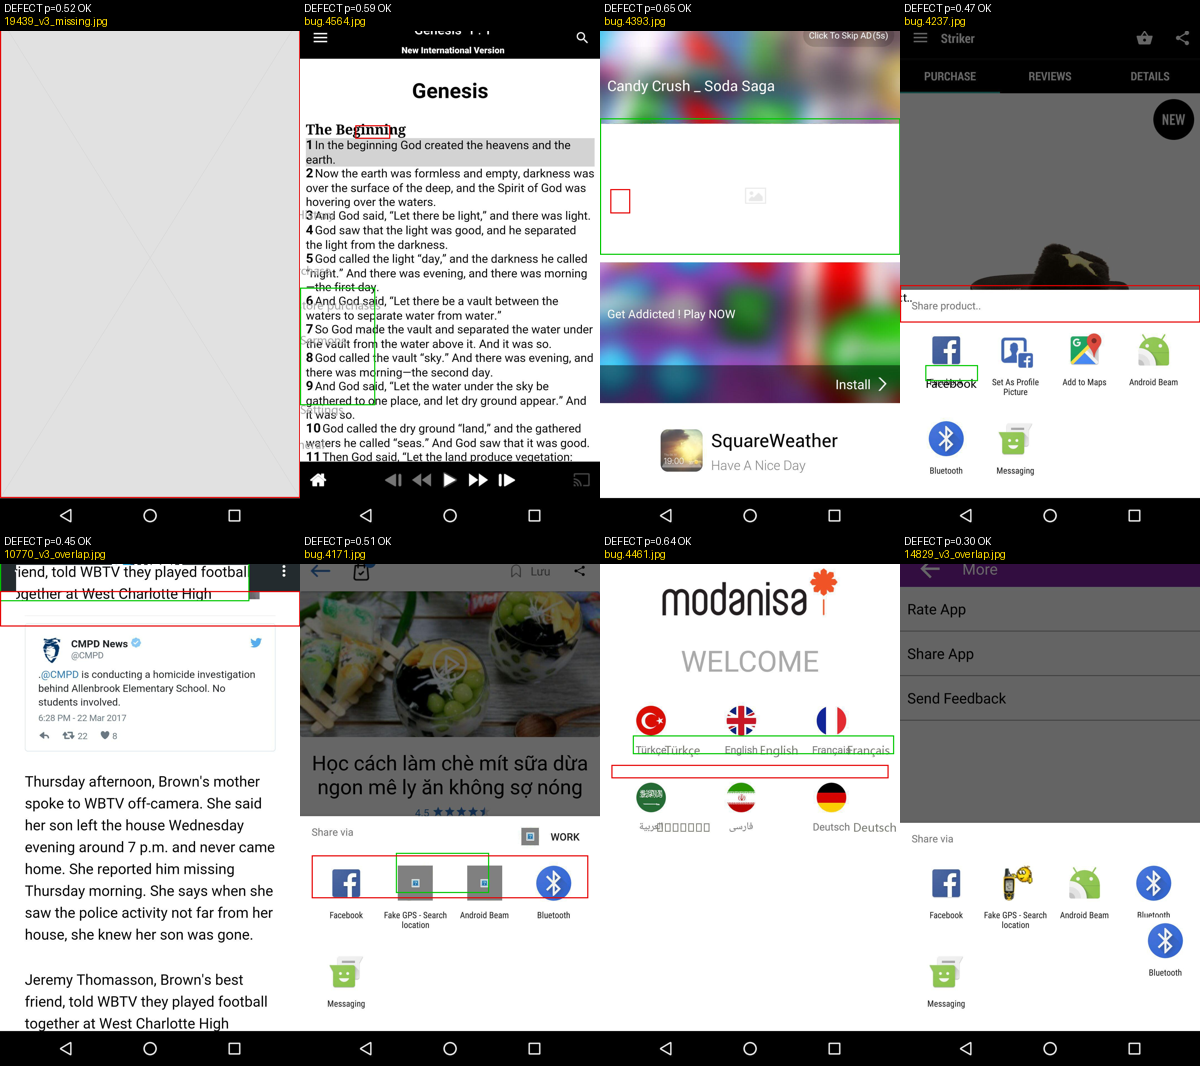

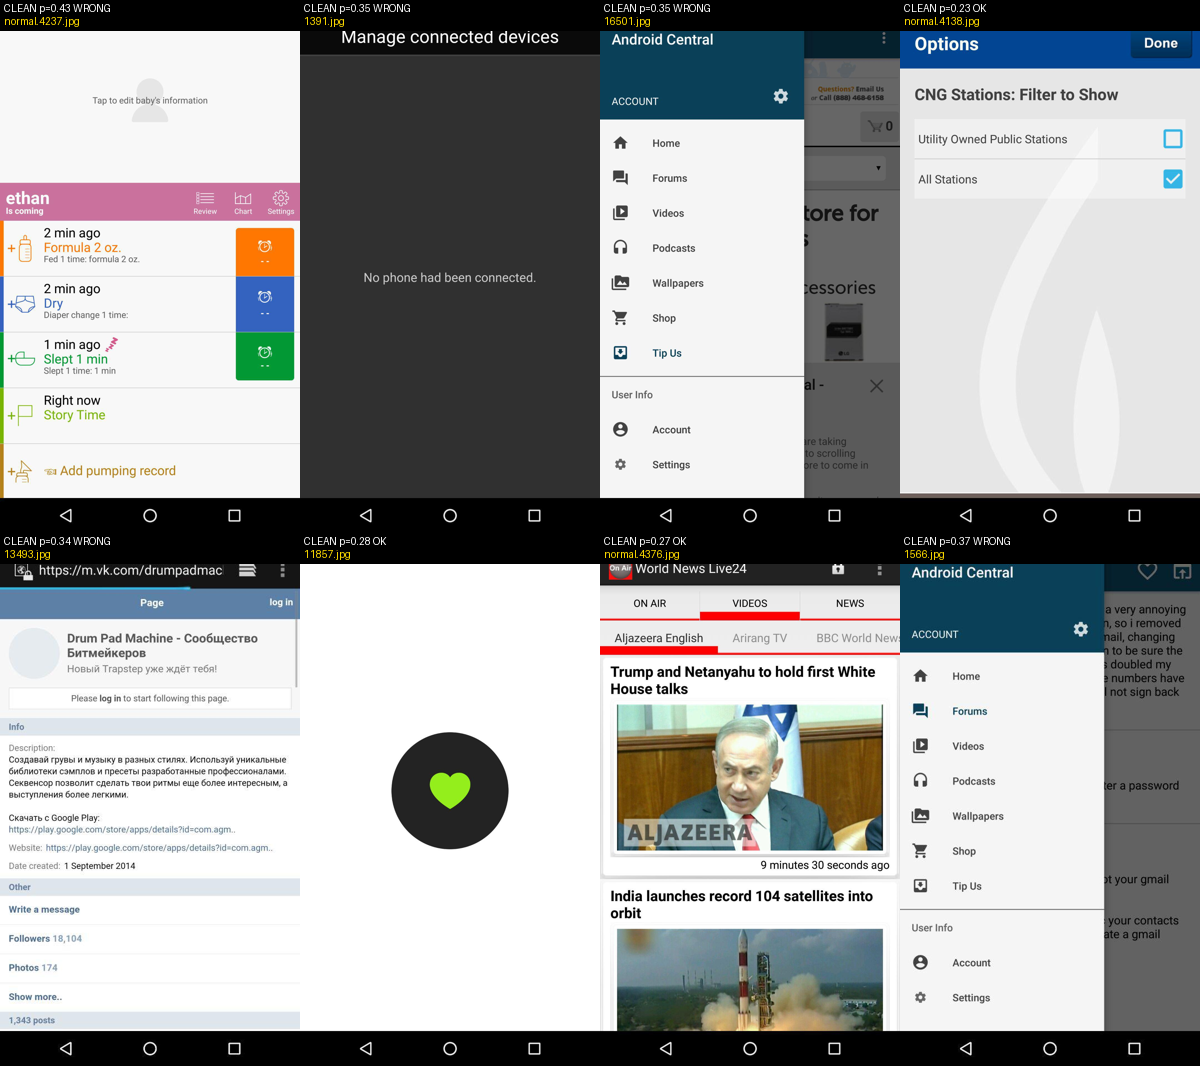

In [9]:
from IPython.display import Image as Img, display
for f in ('spot_defect_screens.png', 'spot_clean_screens.png'):
    p = EV / 'spot_check' / f
    if p.exists(): display(Img(filename=str(p), width=900))

## 8. Training curve and dataset
Loss falls from 0.43 to about 0.30 and then flattens. Loss measures how well the model reproduces the answer text. It is not detection accuracy.

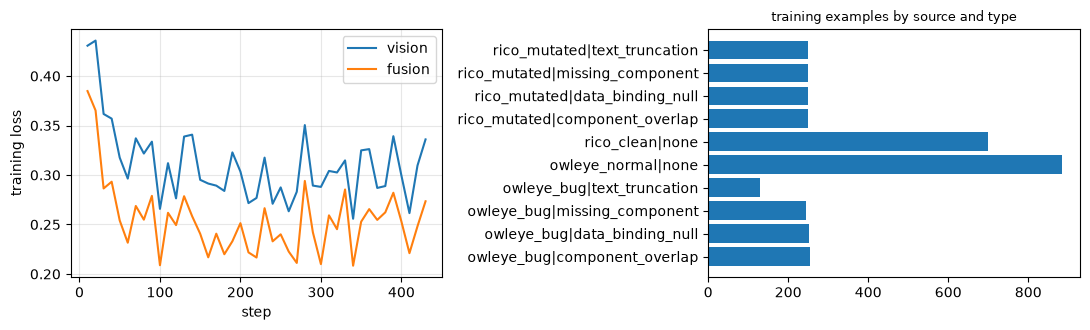

training examples: 3466


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for label, f in (('vision', 'v3_vision_trainer_log.jsonl'), ('fusion', 'v3_fusion_trainer_log.jsonl')):
    p = EV / f
    if p.exists():
        rows = [json.loads(l) for l in p.read_text(encoding='utf-8').splitlines() if l.strip()]
        ax[0].plot([r['current_steps'] for r in rows if 'loss' in r], [r['loss'] for r in rows if 'loss' in r], label=label)
ax[0].set_xlabel('step'); ax[0].set_ylabel('training loss'); ax[0].legend(); ax[0].grid(alpha=.3)
rep = json.loads((C3 / 'evidence' / '12_dataset_v3' / 'dataset_v3_report.json').read_text(encoding='utf-8'))['splits']['train']
names, vals = list(rep), list(rep.values()); ax[1].barh(names, vals); ax[1].set_title('training examples by source and type', fontsize=9); plt.tight_layout(); plt.show()
print('training examples:', sum(vals))

## 8b. Proof that fine-tuning happened
The trainable-parameter counts below are read from the saved adapter files themselves, not from the training logs.

In [11]:
import struct
def adapter_facts(folder):
    cfg = json.loads((folder / 'adapter_config.json').read_text(encoding='utf-8'))
    with open(folder / 'adapter_model.safetensors', 'rb') as f:
        n = struct.unpack('<Q', f.read(8))[0]; header = json.loads(f.read(n))
    params = sum(int(np.prod(v['shape'])) for k, v in header.items() if k != '__metadata__')
    return cfg, params
print(f"{'adapter':<30}{'rank':>5}{'alpha':>6}{'dropout':>9}{'trainable params':>20}")
for name, folder in (('v1 shipped', C3 / 'models' / 'c3_qwen2vl_2b_lora_step246'), ('v3 vision', C3 / 'models' / 'c3_v3_vision_1ep'), ('v3 fusion', C3 / 'models' / 'c3_v3_fusion_1ep')):
    if (folder / 'adapter_model.safetensors').exists():
        cfg, p = adapter_facts(folder)
        print(f"{name:<30}{cfg['r']:>5}{cfg['lora_alpha']:>6}{cfg.get('lora_dropout', 0):>9}{p:>20,}  ({p / 2227450368:.2%} of the 2.23 B base)")
print('base model: Qwen2-VL-2B-Instruct, weights frozen, loaded in 4-bit NF4 (QLoRA); vision encoder frozen')
for label, f in (('vision', 'v3_vision_trainer_log.jsonl'), ('fusion', 'v3_fusion_trainer_log.jsonl')):
    rows = [r for r in (json.loads(l) for l in (EV / f).read_text(encoding='utf-8').splitlines() if l.strip()) if 'loss' in r]
    print(f"{label}: {rows[-1]['total_steps']} steps, first loss {rows[0]['loss']:.2f}, last loss {rows[-1]['loss']:.2f}")

adapter                        rank alpha  dropout    trainable params
v1 shipped                       16    32      0.0          18,464,768  (0.83% of the 2.23 B base)
v3 vision                        16    32     0.05          18,464,768  (0.83% of the 2.23 B base)
v3 fusion                        16    32     0.05          18,464,768  (0.83% of the 2.23 B base)
base model: Qwen2-VL-2B-Instruct, weights frozen, loaded in 4-bit NF4 (QLoRA); vision encoder frozen
vision: 434 steps, first loss 0.43, last loss 0.34
fusion: 434 steps, first loss 0.38, last loss 0.27


## 8c. Are the differences statistically real? (McNemar on paired decisions)
Each model's decision on each test screen is correct or wrong. McNemar's test asks whether two models disagree more in one direction than chance would give. Decisions use each model's fixed threshold from above. p < 0.05 means the difference is unlikely to be luck.

In [12]:
import math
def decisions(label):
    m = MODELS[label]; return {r['image']: ((r['p'] >= m['thr']) == r['gold']) for r in m['recs']}
def mcnemar(a, b):
    da, db = decisions(a), decisions(b); imgs = sorted(set(da) & set(db))
    b_only = sum(da[i] and not db[i] for i in imgs); c_only = sum(db[i] and not da[i] for i in imgs)
    chi = (abs(b_only - c_only) - 1) ** 2 / (b_only + c_only) if b_only + c_only else 0.0
    return b_only, c_only, math.erfc(math.sqrt(chi / 2))
pairs = [('v3 vision (retrained)', 'v1 shipped (before)'), ('v3 vision (retrained)', 'base, screenshot only'),
         ('v3 fusion (+ layout text)', 'v3 vision (retrained)'), ('base, + layout text', 'base, screenshot only')]
print(f"{'A':<28}{'B':<28}{'A right, B wrong':>18}{'B right, A wrong':>18}{'p-value':>10}")
for a, b in pairs:
    if a in MODELS and b in MODELS:
        x, y, p = mcnemar(a, b); print(f"{a:<28}{b:<28}{x:>18}{y:>18}{p:>10.4f}" + ('  *' if p < 0.05 else ''))

A                           B                             A right, B wrong  B right, A wrong   p-value
v3 vision (retrained)       v1 shipped (before)                         69                40    0.0073  *
v3 vision (retrained)       base, screenshot only                      179                85    0.0000  *
v3 fusion (+ layout text)   v3 vision (retrained)                       35                54    0.0564
base, + layout text         base, screenshot only                       11                27    0.0150  *


## 8d. Efficiency on the 4 GB laptop GPU
The decision (defect or not) is one forward pass. Type and box need generation, which is slower. Peak memory includes the 4-bit base model.

In [13]:
print(f"{'model':<24}{'decision median':>17}{'type+box median':>17}{'type+box p95':>14}{'peak GPU memory':>17}")
for label, sf, ef in (('v3 vision', 'v3_test_scores.json', 'v3_e2e_defects122.json'), ('v3 fusion', 'v3_fusion_test_scores.json', 'v3_fusion_e2e_defects122.json'), ('base (untrained)', 'base_vision_test_scores.json', 'base_vision_e2e_defects122.json')):
    s, e = load(sf), load(ef)
    if not (s and e): continue
    dec = np.median([float(r['latency_ms']) for r in s['records']]) / 1000
    print(f"{label:<24}{dec:>15.2f} s{e['summary']['median_latency_ms'] / 1000:>15.1f} s{e['summary']['p95_latency_ms'] / 1000:>12.1f} s{e['peak_vram_bytes'] / 1024 ** 3:>14.2f} GB")
print('target from the proposal: 1.5 s. Met for the defect decision, not when the type and box are generated.')

model                     decision median  type+box median  type+box p95  peak GPU memory
v3 vision                          0.58 s            5.0 s         5.7 s          1.72 GB
v3 fusion                          0.75 s           10.5 s        14.1 s          1.89 GB
base (untrained)                   0.57 s            2.8 s         7.2 s          1.58 GB
target from the proposal: 1.5 s. Met for the defect decision, not when the type and box are generated.


## 8e. Per defect type (type correct, among the 122 test defects)

In [14]:
types = ['component_overlap', 'data_binding_null', 'missing_component', 'text_truncation']
print(f"{'type':<22}" + ''.join(f'{m:>20}' for m in E2E))
for t in types:
    cells = []
    for f in E2E.values():
        d = load(f); pc = d['summary']['per_class'].get(t) if d else None
        cells.append(f"{pc['type_correct']}/{pc['n']} ({pc['type_correct'] / pc['n']:.0%})" if pc else '-')
    print(f'{t:<22}' + ''.join(f'{c:>20}' for c in cells))

type                      base (untrained)           v3 vision           v3 fusion
component_overlap                1/40 (2%)         25/40 (62%)         17/40 (42%)
data_binding_null                0/32 (0%)         31/32 (97%)         31/32 (97%)
missing_component                0/36 (0%)         21/36 (58%)         19/36 (53%)
text_truncation                 2/14 (14%)          2/14 (14%)           0/14 (0%)


## 8f. Same screens, different models: where each one puts its box
Green = true box. Red = v3 vision. Blue = v3 fusion. Orange dashed = untrained base.

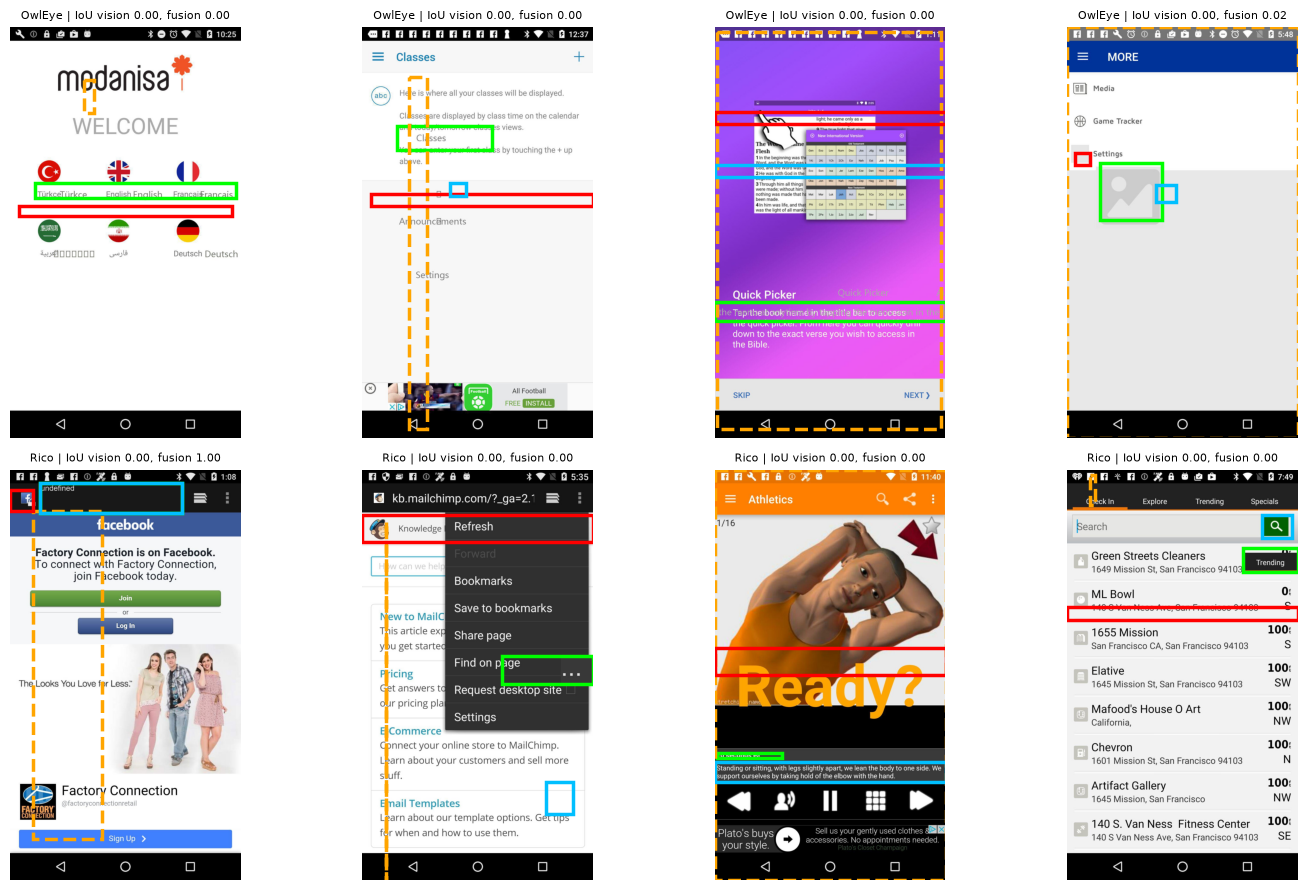

In [15]:
from PIL import Image
E = {k: {r['image']: r for r in load(f)['records']} for k, f in (('vision', 'v3_e2e_defects122.json'), ('fusion', 'v3_fusion_e2e_defects122.json'), ('base', 'base_vision_e2e_defects122.json')) if load(f)}
common = [i for i in E['vision'] if all(i in e for e in E.values()) and E['vision'][i]['pred_box'] and E['vision'][i]['gold_box']]
rng = np.random.default_rng(3)
owl = [i for i in common if 'OwlEye' in i]; rico = [i for i in common if 'OwlEye' not in i]
pick = list(rng.choice(owl, 4, replace=False)) + list(rng.choice(rico, 4, replace=False))
fig, axes = plt.subplots(2, 4, figsize=(15, 9))
def draw(ax, b, w, h, color, ls='-'):
    if not b: return
    y1, x1, y2, x2 = box(b); ax.add_patch(plt.Rectangle((x1 * w / 1000, y1 * h / 1000), (x2 - x1) * w / 1000, (y2 - y1) * h / 1000, fill=False, ec=color, lw=2.5, ls=ls))
for ax, img in zip(axes.ravel(), pick):
    with Image.open(img) as im: im = im.convert('RGB')
    w, h = im.size; ax.imshow(im); ax.axis('off')
    draw(ax, E['vision'][img]['gold_box'], w, h, 'lime'); draw(ax, E['base'][img]['pred_box'], w, h, 'orange', '--')
    draw(ax, E['vision'][img]['pred_box'], w, h, 'red'); draw(ax, E['fusion'][img]['pred_box'], w, h, 'deepskyblue')
    ax.set_title(f"{'OwlEye' if 'OwlEye' in img else 'Rico'} | IoU vision {E['vision'][img]['iou'] or 0:.2f}, fusion {E['fusion'][img]['iou'] or 0:.2f}", fontsize=8)
plt.tight_layout(); plt.show()

## 9. What this does and does not show
- **Fine-tuning helped a lot.** Vision arm vs the untrained base model: AUC +0.22 (95% CI +0.16 to +0.27); vs the earlier model: +0.08 (+0.04 to +0.12). The base model flags about one defect in ten and names the type correctly 2% of the time.
- **Adding the layout as text did not improve detection.** AUC fell from 0.814 to 0.753 (-0.06, CI -0.095 to -0.026). One run, one seed, so part of the gap may be run-to-run variation.
- **Layout and boxes:** tight boxes on Rico rose from 17.5% to 25%, but on only 40 screens that is within noise; on OwlEye screens, which have no layout, fusion was worse. For inserted defects the layout describes the screen before the defect, so it cannot reveal it.
- About half of clean screens are flagged at this alert level, and real defects are rare, so real-world precision would be lower than shown.
- Boxes are in the right area but rarely tight on real screens. One epoch, one seed, model-assisted labels.
